# matplotlib 的进阶用法

In [1]:
import numpy as np
import helper.matplotlib
from matplotlib import pyplot as plt

## 本章要学的内容

到前面为止，常用的画法应该已经清楚了，这一章围绕坐标变换与注释，说明怎样把图做到想要的样子。

- 4 个坐标系与变换
- 填充与带箭头的注释
- 变换的部件(`transData` 的内容)
- 加阴影、放文字
- 用 AGG 直接绘制、动画

## 坐标变换与注释

一张图里牵涉到好几个坐标系与变换，理清各自的含义，文字与箭头的位置就能随便定，这一节以注释为例说明坐标系与变换。

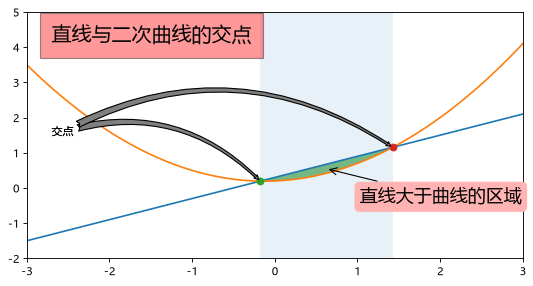

In [2]:
def func1(x):  #❶
    return 0.6 * x + 0.3


def func2(x):  #❶
    return 0.4 * x * x + 0.1 * x + 0.2


def find_curve_intersects(x, y1, y2):
    d = y1 - y2
    idx = np.where(d[:-1] * d[1:] <= 0)[0]
    x1, x2 = x[idx], x[idx + 1]
    d1, d2 = d[idx], d[idx + 1]
    return -d1 * (x2 - x1) / (d2 - d1) + x1


x = np.linspace(-3, 3, 100)  #❷
f1 = func1(x)
f2 = func2(x)
fig, ax = plt.subplots(figsize=(8, 4), dpi=80)
ax.plot(x, f1)
ax.plot(x, f2)

x1, x2 = find_curve_intersects(x, f1, f2)  #❸
ax.plot(x1, func1(x1), "o")
ax.plot(x2, func1(x2), "o")

ax.fill_between(x, f1, f2, where=f1 > f2, facecolor="green", alpha=0.5)  #❹

from matplotlib import transforms

trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)
ax.fill_between([x1, x2], 0, 1, transform=trans, alpha=0.1)  #❺

a = ax.text(
    0.05,
    0.95,
    "直线与二次曲线的交点",  #❻
    transform=ax.transAxes,
    verticalalignment="top",
    fontsize=18,
    bbox={"facecolor": "red", "alpha": 0.4, "pad": 10},
)

arrow = {
    "arrowstyle": "fancy,tail_width=0.6",
    "facecolor": "gray",
    "connectionstyle": "arc3,rad=-0.3",
}

ax.annotate(
    "交点",  #❼
    xy=(x1, func1(x1)),
    xycoords="data",
    xytext=(0.05, 0.5),
    textcoords="axes fraction",
    arrowprops=arrow,
)

ax.annotate(
    "交点",  #❼
    xy=(x2, func1(x2)),
    xycoords="data",
    xytext=(0.05, 0.5),
    textcoords="axes fraction",
    arrowprops=arrow,
)

xm = (x1 + x2) / 2
ym = (func1(xm) - func2(xm)) / 2 + func2(xm)
o = ax.annotate(
    "直线大于曲线的区域",  #❼
    xy=(xm, ym),
    xycoords="data",
    xytext=(30, -30),
    textcoords="offset points",
    bbox={"boxstyle": "round", "facecolor": (1.0, 0.7, 0.7), "edgecolor": "none"},
    fontsize=16,
    arrowprops={"arrowstyle": "->"},
)

ax.set_xlim(-3, 3)
ax.set_ylim(-2, 5);

这张图里加了下面这些注释。

* 用两个小点标出直线与曲线的交点。
* 在两个交点之间，把两条线之间的区域填上颜色。
* 为了标出两个交点之间的范围，画一个高度是整块子图、左右两边穿过交点的长方形。
* 左上角放一段说明的文字。
* 在交点与填充的部分加带箭头的注释。

先 ❶ 定义直线与二次曲线的函数 `func1`、`func2`，❷ 在区间 `(-3, 3)` 上计算，用 `plot()` 画出来。

❸ 为了标出交点，用 `find_curve_intersects()` 求两条曲线的交点的 x 坐标 `x1`、`x2`；交点本身用 `plot()` 画：x 与 y 各给一个数，格式设成 `'o'`。

:::{admonition} 求两条曲线的交点
:class: note
如果两条曲线的 y 是在同一串 x 上算出来的，交点就很容易求：先算差 `d = y1 - y2`，找出符号变化的相邻两点 `idx` 与 `idx + 1`，线段 `(x[idx], d[idx])`〜`(x[idx+1], d[idx+1])` 与 x 轴的交点就是曲线交点的 x 坐标 `xc`，y 则用 `np.interp(xc, x, y1)` 插值求得。
:::

❹ 用 `fill_between()` 在 x 轴上填两个交点之间、在 y 轴上填两条曲线之间的区域，颜色与透明度由 `facecolor` 与 `alpha` 决定。调用方式如下。

```python
fill_between(x, y1, y2=0, where=None)
```

`x` 是长度 `N` 的数组，`y1` 与 `y2` 是长度 `N` 的数组或者一个数，是数的时候就当作全同值的数组；`where` 为 `None` 时全部填，给真假数组时只填 `True` 的地方。这里 `where = f1 > f2`，填的只是直线在曲线上方的部分。

❺ 画出两个交点之间的长方形，❻ 用 `text()` 放说明的文字，❼ 最后用 `annotate()` 加带箭头的注释。

要真正理解这个程序，得先知道坐标变换的机制。

### 4 个坐标系

一张图里有 4 个坐标系。

* 数据坐标系：数据所在空间里的位置，这张图里 x 是 `(-3, 3)`、y 是 `(-2, 5)`。
* 子图坐标系：子图内部的位置，左下角是 `(0, 0)`、右上角是 `(1, 1)`。
* 图坐标系：整张图内部的位置，因为子图周围有留白，还需要表示整张图的坐标，左下角是 `(0, 0)`、右上角是 `(1, 1)`。
* 窗口坐标系：绘制窗口里的像素，左下角是 `(0, 0)`、右上角是 `(宽, 高)`，不含标题栏等部分。

`Axes` 的 `transData` 是数据坐标的变换、`transAxes` 是子图坐标的变换，`Figure` 的 `transFigure` 则是图坐标的变换。

用变换对象的 `transform()` 能把那个坐标变成窗口坐标，下面的程序把数据坐标的 `(-3, -2)` 与 `(3, 5)` 变成窗口坐标。

In [3]:
print(type(ax.transData))
ax.transData.transform([(-3, -2), (3, 5)])

<class 'matplotlib.transforms.CompositeGenericTransform'>


array([[ 80. ,  35.2],
       [576. , 281.6]])

下面的程序把子图坐标的 `(0, 0)` 与 `(1, 1)` 变成窗口坐标，结果与上面相同：也就是说，子图的左下角与数据坐标的 `(-3, -2)` 在画面上是同一个点。

In [4]:
ax.transAxes.transform([(0, 0), (1, 1)])

array([[ 80. ,  35.2],
       [576. , 281.6]])

最后把图坐标的 `(0, 0)` 与 `(1, 1)` 变成窗口坐标，由此可知绘图的区域是 640×320 像素。

In [5]:
fig.transFigure.transform([(0, 0), (1, 1)])

array([[  0.,   0.],
       [640., 320.]])

用 `inverted()` 能取到相反的变换，下面的程序把窗口坐标的 `(320, 160)` 变成数据坐标。

In [6]:
inv = ax.transData.inverted()
print(type(inv))
inv.transform((320, 160))

<class 'matplotlib.transforms.CompositeGenericTransform'>


array([-0.09677419,  1.54545455])

先看这张图：子图的留白上下左右各不相同，绘图的中心 `(320, 160)` 因此并不是数据的中心 `(0, 1.5)`。

用 `set_xlim()` 改变显示范围，数据坐标的变换也会跟着变。

In [7]:
print(ax.set_xlim(-3, 2))  # 把 x 轴的范围设成 -3 到 2
print(ax.transData.transform((3, 5)))  # 数据坐标的变换对象已经变了

(-3.0, 2.0)
[675.2 281.6]


看上面那张图里画长方形的地方。

```python
from matplotlib import transforms
trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)
ax.fill_between([x1, x2], 0, 1, transform=trans, alpha=0.1)
```

左右两边要穿过交点，因此 x 用数据坐标的 `x1`、`x2`；高度要撑满子图，y 则用子图坐标的 0 与 1。

:::{tip}
垂直或水平的带子用 `axvspan()` 与 `axhspan()` 画起来更简单。
:::

这种混合的坐标系用 `blended_transform_factory()` 来做：两个参数都是变换，x 的变换取自第 1 个、y 的取自第 2 个，返回的 `trans` 就是 x 用数据坐标、y 用子图坐标的变换。把它传给 `fill_between()` 的 `transform`，左右两边就穿过交点、上下贴着子图的边框。

### 变换的流水线

换一个坐标系要经过好几个阶段，数据坐标不一定是直角坐标，也可能是极坐标或对数坐标，变换因此并不是简单的二维仿射变换。先从这个最简单的 `transFigure` 来看 matplotlib 的变换流程。

用本书的 `GraphvizMPLTransform` 能把变换的关系画成图，下面这张图是 `fig.transFigure` 的内容。

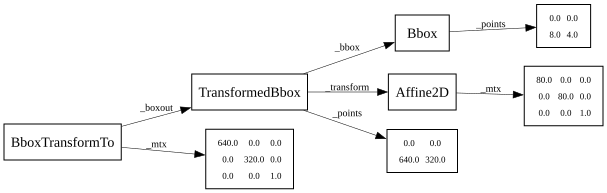

In [8]:
from helper.dot import GraphvizMPLTransform
import graphviz

graphviz.Source(GraphvizMPLTransform.graphviz(fig.transFigure))

这个变换是 `BboxTransformTo`，它里面放着 `TransformedBbox`，而 `TransformedBbox` 又有 `Bbox` 与 `Affine2D`。

* `Bbox`：长方形 `[[x0, y0], [x1, y1]]`，这个例子里是 `(0, 0)` 与 `(8, 4)`，也就是图的英寸尺寸(`figsize`)。
* `Affine2D`：二维的仿射变换，也就是矩阵；非对角元素是 0，只做放大，把 `(x, y)` 变成 `(80*x, 80*y)`。

:::{admonition} 仿射变换
:class: note
二维仿射变换的矩阵是 $3 \times 3$ 的，用的是齐次坐标：点 `(x, y)` 写成 `(x, y, 1)` 再乘矩阵。最下面一行永远是 `(0, 0, 1)`，因此也可以写成 $2 \times 3$。

$$\begin{pmatrix} x' \\ y' \\ 1 \end{pmatrix} = \begin{pmatrix} a_{00} & a_{01} & b_0 \\ a_{10} & a_{11} & b_1 \\ 0 & 0 & 1 \end{pmatrix} \begin{pmatrix} x \\ y \\ 1 \end{pmatrix}$$
:::

* `TransformedBbox`：长方形经过仿射变换之后的长方形，这个例子里顶点是 `(0, 0)` 与 `(640, 320)`；为了不重复计算，把顶点记在 `_points` 里。这已经是像素的大小，矩阵里的 80 就是 `Figure` 的 `dpi`。
* `BboxTransformTo`：从单位长方形到指定长方形的变换，这个例子里把 `(0, 0)-(1, 1)` 变成 `(0, 0)-(640, 320)`，于是图坐标就能变成窗口坐标；矩阵记在 `_mtx` 里。

`fig.transFigure` 的仿射变换可以用 `fig.dpi_scale_trans` 取到。

In [9]:
fig.dpi_scale_trans == fig.transFigure._boxout._transform

np.True_

接着看子图坐标的变换里有什么。

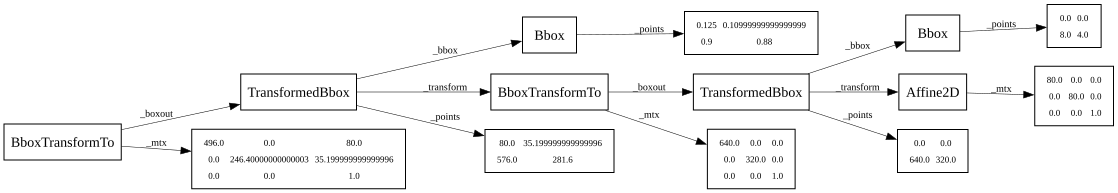

In [10]:
graphviz.Source(GraphvizMPLTransform.graphviz(ax.transAxes))

`ax.transAxes` 是 `BboxTransformTo`，把 `(0, 0)-(1, 1)` 变成另一个长方形；那个长方形是 `TransformedBbox`，由 `(0.125, 0.1)-(0.9, 0.9)` 经 `fig.transFigure` 变换而来。也就是说，`transAxes` 里面用的是 `transFigure`。

In [11]:
ax.transAxes._boxout._transform == fig.transFigure

np.True_

这个变换途中的长方形 `(0.125, 0.11)-(0.9, 0.88)`，就是子图在图坐标里的位置。

In [12]:
ax.get_position()

Bbox([[0.125, 0.10999999999999999], [0.9, 0.88]])

子图在窗口坐标里的长方形如下。

In [13]:
ax.transAxes._boxout.bounds

(np.float64(80.0),
 np.float64(35.199999999999996),
 np.float64(496.0),
 np.float64(246.40000000000003))

也就是说 `ax.transAxes` 是把 `(0, 0)-(1, 1)` 变成 `(80.0, 35.2)-(496.0, 246.4)` 的变换。

最后看数据坐标的 `ax.transData`：它由 `transScale`、`transLimits`、`transAxes` 构成，先看 `transLimits` 与 `transScale`。`transLimits` 是 `BboxTransformFrom`，把指定的长方形变成 `(0,0)-(1,1)`。

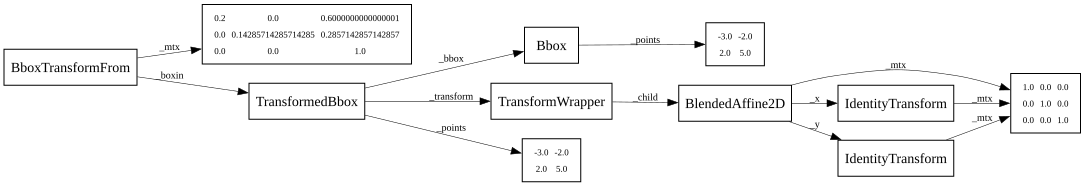

In [14]:
graphviz.Source(GraphvizMPLTransform.graphviz(ax.transLimits))

`transLimits` 原来的长方形是 `TransformedBbox`，由 `(-3, -2)-(2, 5)` 变换而来；这里的变换是 `TransformWrapper`，在上面的图里是恒等变换。所以 `transLimits` 就是把 `(-3, -2)-(2, 5)` 变成 `(0, 0)-(1, 1)`。

In [15]:
print(ax.transLimits.transform((-3, -2)))
print(ax.transLimits.transform((2, 5)))

[0. 0.]
[1. 1.]


长方形 `(-3, -2)-(2, 5)` 由轴的显示范围决定。

In [16]:
print(ax.get_xlim())  # 取 x 轴的显示范围
print(ax.get_ylim())  # 取 y 轴的显示范围

(np.float64(-3.0), np.float64(2.0))
(np.float64(-2.0), np.float64(5.0))


`transLimits` 把数据的范围变成单位长方形，`transAxes` 再把它变成像素的长方形，合起来数据坐标就变成了窗口坐标。两个变换用 `+` 连起来：`ax.transLimits + ax.transAxes` 的意思是先做 `transLimits`、再做 `transAxes`，变换就像工厂的流水作业一样，把坐标一段段地改过去。下面的程序把结果与 `ax.transData` 的结果相比较。

In [17]:
t = ax.transLimits + ax.transAxes
print(t.transform((0, 0)))
print(ax.transData.transform((0, 0)))

[377.6 105.6]
[377.6 105.6]


为了能改轴的缩尺，`transData` 里还有 `transScale`，也就是 `transData = transScale + transLimits + transAxes`。这个例子里 `transScale` 是恒等变换，所以 `ax.transLimits + ax.transAxes` 与 `ax.transData` 的结果相同。

In [18]:
ax.transScale

用 `semilogx()`、`semilogy()`、`loglog()` 画对数轴的图时，或者用 `set_xscale()`、`set_yscale()` 改成对数时，`transScale` 就不是恒等变换了，内容变成下面这张图的样子。

:::{warning}
这个例子里 x 的范围是 `(-3, 3)`，把 x 轴改成对数时，负值会引出一大堆错误。
:::

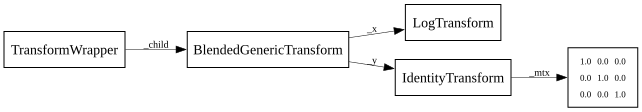

In [19]:
ax.set_xscale("log")  # 把 x 轴改成对数坐标
graphviz.Source(GraphvizMPLTransform.graphviz(ax.transScale))

In [20]:
ax.set_xscale("linear")  # 把 x 轴改成线性坐标

### 加阴影

用上一节的变换来画带阴影的曲线。

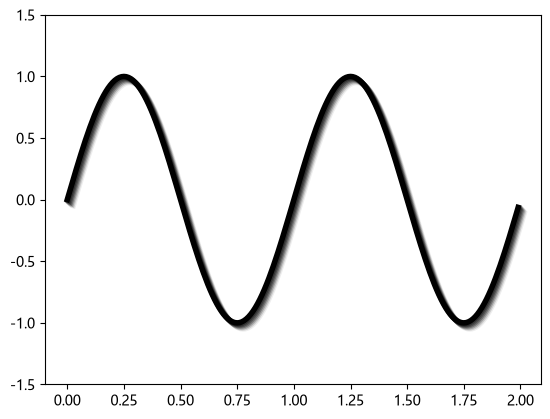

In [21]:
fig, ax = plt.subplots()
x = np.arange(0.0, 2.0, 0.01)
y = np.sin(2 * np.pi * x)

N = 7  # 阴影的条数
for i in range(N, 0, -1):
    offset = transforms.ScaledTranslation(i, -i, transforms.IdentityTransform())  #❶
    shadow_trans = plt.gca().transData + offset  #❷
    ax.plot(
        x,
        y,
        linewidth=4,
        color="black",
        transform=shadow_trans,  #❸
        alpha=(N - i) / 2.0 / N,
    )

ax.plot(x, y, linewidth=4, color="black")
ax.set_ylim((-1.5, 1.5));

画 N 条透明度与位置各差一点的曲线，最后再画真正的曲线，看起来就像阴影。

❶ `offset` 是 `ScaledTranslation`，前两个参数是 x 与 y 的偏移、第 3 个是变换；这里第 3 个是恒等变换，作用只是把 x 加 `i`、y 减 `i`。

下面是 `i` 为 1 时的 `offset`。

In [22]:
offset.transform((0, 0))  # 把 (0,0) 变成 (1,-1)

array([ 1., -1.])

❷ 阴影曲线的变换是 `shadow_trans`，由数据坐标的变换 `transData` 与 `offset` 组成。

In [23]:
print(ax.transData.transform((0, 0)))  # 按数据坐标变换 (0,0)
print(shadow_trans.transform((0, 0)))  # 按数据坐标变换 (0,0)再加偏移变换

[102.54545455 237.6       ]
[103.54545455 236.6       ]


❸ 最后把 `shadow_trans` 传给 `plot()` 的 `transform`：它在数据坐标变成窗口坐标之后再挪位置，这样放大时阴影的样子不会变。

### 加注释

`pyplot` 里有两个放文字的函数：`text()` 调用当前 `Axes` 的，`figtext()` 调用当前 `Figure` 的；`text()` 放在数据坐标上、`figtext()` 放在图坐标上，都可以用 `transform` 换坐标系。下面的程序在 3 个坐标系上放文字。

Text(0.1, 0.92, '图坐标系里的文字')

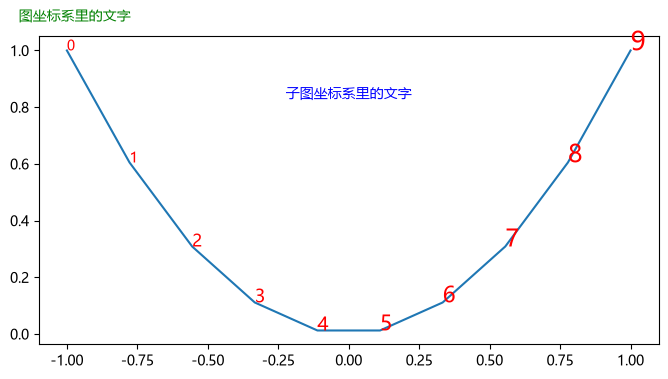

In [24]:
x = np.linspace(-1, 1, 10)
y = x**2

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y)

for i, (_x, _y) in enumerate(zip(x, y)):
    ax.text(_x, _y, str(i), color="red", fontsize=i + 10)  #❶

ax.text(
    0.5,
    0.8,
    "子图坐标系里的文字",
    color="blue",
    ha="center",
    transform=ax.transAxes,
)  #❷

plt.figtext(0.1, 0.92, "图坐标系里的文字", color="green")  #❸;

❶ 没有传 `transform`，`text()` 就放在数据坐标上，用 `fontsize` 改大小。❷ 设成 `transform=ax.transAxes` 就放在子图坐标上，`ha` 是水平方向的对齐方式，`'center'` 时 `(0.5, 0.8)` 是文字的中心。❸ `figtext()` 放在图坐标上。

缩放或平移时，数据坐标的文字跟着曲线动，另外两个不动；改子图的留白时，子图坐标的文字跟着子图的中心动；图坐标的文字只在窗口大小变化时动。

文字的函数里有很多决定文字与边框外观的参数，详细请看官方的说明。

用 `annotate()` 画带箭头的注释，调用方式如下。

```python
annotate(s, xy, xytext=None, xycoords='data', textcoords='data', arrowprops=None, ...)
```

其中 `s` 是注释的文字、`xy` 是箭头尖端的坐标、`xytext` 是文字的坐标，`xycoords` 与 `textcoords` 分别决定两者的坐标系。

两个坐标可以放在不同的坐标系里，能指定的值如下。

| 值  | 含义  |
|:--|:--|
| `figure points`  | 从图的左下角起，按点为单位 |
| `figure pixels`  | 从图的左下角起，按像素为单位 |
| `figure fraction`  | 图坐标 |
| `axes points`  | 从子图的左下角起，按点为单位 |
| `axes pixels`  | 从子图的左下角起，按像素为单位 |
| `axes fraction`  | 子图坐标 |
| `data`  | 数据坐标 |
| `offset points`  | 从指定的点起，按点为单位偏移 |
| `offset pixels`  | 从指定的点起，按像素为单位偏移 |

## 技巧

最后介绍几个特别的用法。

### 用 agg 后端绘制

matplotlib 的图之所以好看，是因为用了 C++ 写的抗锯齿绘图库 Anti-Grain Geometry(AGG)。只画二维图形时，可以在内存里画好再变成 NumPy 数组。

下面的代码做出 250×250 像素的 `RendererAgg`(画布)，第 3 个参数是 dpi，不影响画布的大小。用 `buffer_rgba()` 取到绘制结果的缓冲区，用 `np.frombuffer()` 变成数组再 `reshape()`；`arr` 的形状是 `(250, 250, 4)`，其中 4 是红、绿、蓝与透明度的 4 个通道。

In [25]:
import numpy as np
from matplotlib.backends.backend_agg import RendererAgg

w, h = 250, 250
renderer = RendererAgg(w, h, 90)
buf = renderer.buffer_rgba()
arr = np.frombuffer(buf, np.uint8).reshape(h, w, -1)
print(arr.shape)

(250, 250, 4)


`RendererAgg` 有各种 `draw_*()` 的绘制方法。下面的代码做出 `Path`，再用 `draw_path()` 画：第 1 个参数是决定线宽与颜色的 `GraphicsContextBase`、第 3 个是坐标变换(这里是恒等变换)、第 4 个是填充的颜色。

In [26]:
from matplotlib.path import Path
from matplotlib import transforms

path_data = [
    (Path.MOVETO, (179, 1)),
    (Path.CURVE4, (117, 75)),
    (Path.CURVE4, (12, 230)),
    (Path.CURVE4, (118, 230)),
    (Path.LINETO, (142, 187)),
    (Path.CURVE4, (210, 290)),
    (Path.CURVE4, (250, 132)),
    (Path.CURVE4, (200, 105)),
    (Path.CLOSEPOLY, (179, 1)),
]

code, points = zip(*path_data)
path = Path(points, code)

gc = renderer.new_gc()
gc.set_linewidth(2)
gc.set_foreground((1, 0, 0))
gc.set_antialiased(True)
renderer.draw_path(gc, path, transforms.IdentityTransform(), (0, 1, 0))

也能用 `Artist` 来画：下面的代码做出 `Circle` 与 `Text`，分别用 `draw()` 画。`Text` 在画的时候要读画布的 `dpi`，因此在 `draw()` 之前要先把 `renderer` 放进它的 `figure` 属性里。

In [27]:
from matplotlib.patches import Circle
from matplotlib.text import Text

c = Circle(
    (w / 2, h / 2), 50, edgecolor="blue", facecolor="yellow", linewidth=2, alpha=0.5
)
c.draw(renderer)

renderer.get_figure = lambda root=True:renderer
text = Text(w / 2, h / 2, "Circle", va="center", ha="center")
text.figure = renderer
text.draw(renderer)

要在 Notebook 里显示 `arr` 的图像就用 `plt.imsave()`，第 1 个参数是文件名或文件对象；这里把 PNG 写进 `BytesIO`，再用 `display_png()` 显示。

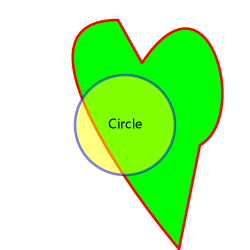

In [28]:
from io import BytesIO
from IPython.display import display_png

png_buf = BytesIO()
plt.imsave(png_buf, arr, format="png")
display_png(png_buf.getvalue(), raw=True)

本书准备了一个在图像上绘制的 `ImageDrawer`，下面的例子在图像上画标记、文字、直线、圆、长方形与椭圆，再用 `%array_image` 魔法命令显示。

`ImageDrawer` 的 `reverse` 是 y 轴的方向，默认是 `True`，y 朝下，与图像像素的坐标一致；设成 `False` 时 y 朝上，与数学的坐标一致。

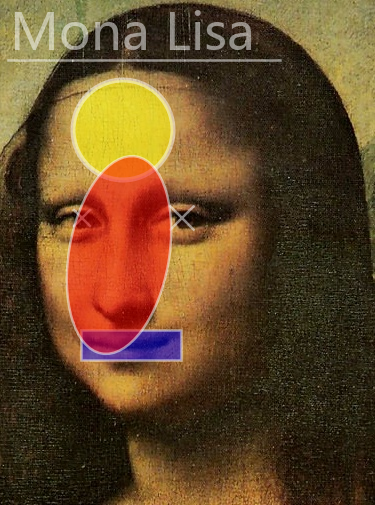

In [29]:
from helper.matplotlib import ImageDrawer
from helper.numpy import array_image

img = plt.imread("data/vinci_target.png")
drawer = ImageDrawer(img)
drawer.set_parameters(lw=2, color="white", alpha=0.5)
drawer.line(8, 60, 280, 60)
drawer.circle(123, 130, 50, facecolor="yellow", lw=4)
drawer.markers("x", [82, 182], [218, 218], [50, 100])
drawer.rectangle(81, 330, 100, 30, facecolor="blue")
drawer.text(10, 50, "Mona Lisa", fontsize=40)
drawer.ellipse(119, 255, 200, 100, 100, facecolor="red")
array_image(drawer.to_array())

### 动画

改掉部件的属性再重画，就成了简单的动画，下面的例子是这样做的。

❶ 做出 50 毫秒的定时器，用 `add_callback()` 登记函数：第 1 个参数是要调用的函数、第 2 个是传给它的对象。因为要改曲线的数据，传进的是 `Line2D` 的 `line`，❷ 用 `set_ydata()` 改 y 的数据。❸ 用 `canvas.draw()` 把整张图重画一遍。

:::{tip}
要在 JupyterLab 里交互地动起来，就装上 `ipympl`，在格子里执行下面的魔法命令。

```bash
pip install ipympl
```

```python
%matplotlib ipympl
```
:::

In [30]:
%matplotlib ipympl

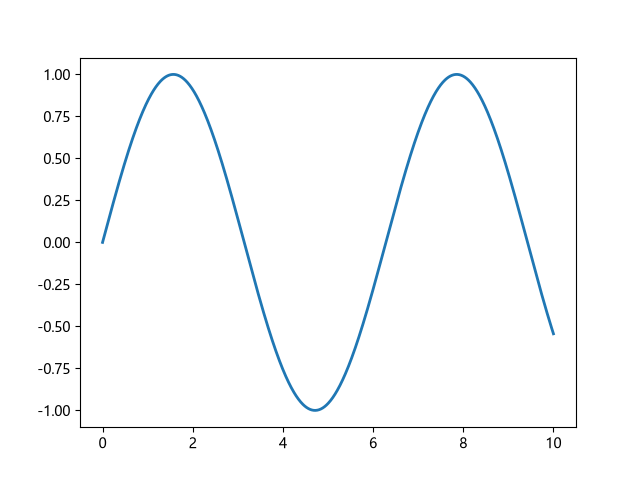

In [31]:
from matplotlib import pyplot as plt
import numpy as np

fig, ax = plt.subplots()
x = np.linspace(0, 10, 1000)
(line,) = ax.plot(x, np.sin(x), lw=2)


def update_data(line):
    x[:] += 0.1
    line.set_ydata(np.sin(x))  #❷
    fig.canvas.draw()  #❸


timer = fig.canvas.new_timer(interval=50)  #❶
timer.add_callback(update_data, line)
timer.start()

定时器用下面的代码停掉。

In [32]:
timer.stop()

#### 用缓存加快重画

`canvas.draw()` 很慢，让不动的地方原样留着、只重画会动的部分就快了。下面的例子是这样做的。

❶ 做部件时把 `animated=True` 设上，❷ `canvas.draw()` 不画 `animated` 为 `True` 的对象。❸ 画完静态的部分之后，用 `copy_from_bbox()` 把子图那块区域的图像存进 `background`，位置与大小从 `bbox` 取。

定时器的函数里 ❹ 用 `restore_region()` 回到存下的图像，效果等于擦掉会动的部分、重画静态的部分。❺ 改完 y 的数据再用 `draw_artist()` 把曲线画到画布上，❻ 用 `blit()` 把画布的那块区域送到画面。

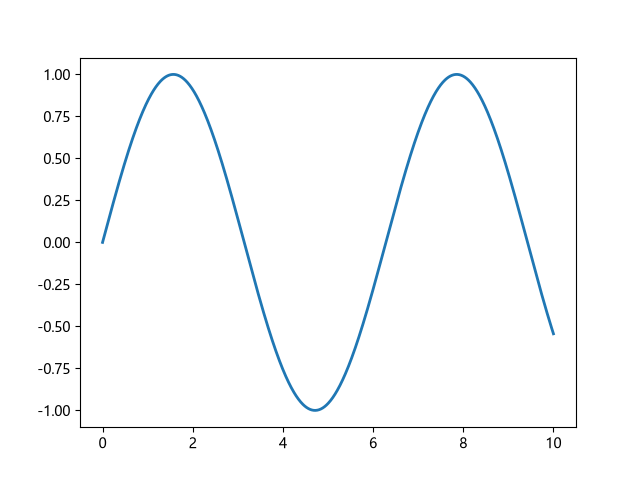

In [33]:
fig, ax = plt.subplots()
x = np.linspace(0, 10, 1000)
(line,) = ax.plot(x, np.sin(x), lw=2, animated=True)  #❶

fig.canvas.draw()  #❷
background = fig.canvas.copy_from_bbox(ax.bbox)  #❸


def update_data(line):
    x[:] += 0.1
    line.set_ydata(np.sin(x))
    fig.canvas.restore_region(background)  #❹
    ax.draw_artist(line)  #❺
    fig.canvas.blit(ax.bbox)  #❻


timer = fig.canvas.new_timer(interval=50)
timer.add_callback(update_data, line)
timer.start()

In [34]:
timer.stop()

#### `animation` 模块

到前面两个例子为止，机制已经清楚了，不过平时都用 `animation` 模块：`FuncAnimation` 按固定的间隔调用函数，更新图里的部件。

❶ 做曲线时把 `animated=True` 设上。❷ 在更新用的函数 `update_line()` 里把数据填进会动的部件：参数会收到帧的编号，用它改相位，再返回会动的部件的排列。❸ 做出 `FuncAnimation`，定期调用 `update_line()`：`interval` 是 1 帧的毫秒数，`blit=True` 用缓存加速，`frames` 是帧数。

In [35]:
%matplotlib inline

In [36]:
from matplotlib.animation import FuncAnimation

plt.ioff()
fig, ax = plt.subplots()

x = np.linspace(0, 4 * np.pi, 200)
y = np.sin(x)
(line,) = ax.plot(x, y, lw=2, animated=True)  #❶


def update_line(i):
    y = np.sin(x + i * 2 * np.pi / 100)
    line.set_ydata(y)
    return [line]  #❷


ani = FuncAnimation(fig, update_line, blit=True, interval=25, frames=100)  #❸

要存成视频文件，就像下面这样调用。

:::{warning}
matplotlib 用系统里装的视频压缩软件(`ffmpeg.exe` 等)来做视频，请确认它的可执行文件所在文件夹在 `PATH` 里。
:::

In [37]:
ani.save("sin_wave.mp4", fps=25)

做出来的动画如下。

In [38]:
from IPython.display import Video

Video("sin_wave.mp4", embed=True)

## 小结

* 图里有 4 个坐标系：数据、子图、图、窗口。
* 用 `transData`、`transAxes`、`transFigure` 能把坐标变成窗口坐标，用 `inverted()` 还能取到相反的变换。
* x 与 y 用不同坐标系时，用 `blended_transform_factory()` 混合。
* `transData` 是 `transScale` + `transLimits` + `transAxes`，对数轴时 `transScale` 才起作用。
* 文字用 `text()`(数据坐标)与 `figtext()`(图坐标)，带箭头的是 `annotate()`，坐标系用 `xycoords` 与 `textcoords` 决定。
* 用 `RendererAgg` 可以不用图，直接画二维的图再变成数组。
* 动画是用定时器改数据再重画，想快就用 `animated` 与 `blit`，平时用 `FuncAnimation`。